In [ ]:
!pip install -q pycaret

In [ ]:
!wget -O phiusiil.zip "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
!unzip -o phiusiil.zip
!ls

--2026-10-16 08:14:31--  https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘phiusiil.zip’

phiusiil.zip            [          <=>       ]  14.66M  7.48MB/s    in 2.0s    

2026-10-16 08:14:33 (7.48 MB/s) - ‘phiusiil.zip’ saved [15376007]

Archive:  phiusiil.zip
  inflating: PhiUSIIL_Phishing_URL_Dataset.csv  
logs.log  PhiUSIIL_Phishing_URL_Dataset.csv  phiusiil.zip  sample_data


In [ ]:
DATA_PATH = "PhiUSIIL_Phishing_URL_Dataset.csv"

In [ ]:
SAMPLE_N = 50000     # quick first run; change to None for the final run
SEED = 42

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pycaret.classification import *

In [ ]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)

Shape: (235795, 56)


In [ ]:
# 2. DATA QUALITY AUDIT
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate URLs:", int(df["URL"].duplicated().sum()))
print("\nColumn types:\n", df.dtypes.value_counts())
print("\nClass distribution (1 = legitimate, 0 = phishing):")
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

Missing values: 0
Duplicate rows: 0
Duplicate URLs: 425

Column types:
 int64      41
float64    10
object      5
Name: count, dtype: int64

Class distribution (1 = legitimate, 0 = phishing):
label
1    134850
0    100945
Name: count, dtype: int64
label
1    0.572
0    0.428
Name: proportion, dtype: float64


In [ ]:

# 3. PREPROCESSING
data = df.copy()

In [ ]:
# 3.1 Remove duplicates / missing values
before = len(data)
data = data.drop_duplicates(subset="URL").dropna().reset_index(drop=True)
print(f"\nRows removed (duplicates/missing): {before - len(data)}")


Rows removed (duplicates/missing): 425


In [ ]:
# 3.4 Remove constant columns
nunique = data.drop(columns="label").nunique()
const_cols = nunique[nunique <= 1].index.tolist()
data = data.drop(columns=const_cols)
print("Dropped constant columns:", const_cols)

Dropped constant columns: []


In [ ]:
# 3.5 Remove highly correlated features (|r| > 0.95)
remove_multicollinearity=True

In [ ]:
from pycaret.classification import *

features_before = [c for c in data.columns if c != "label"]

setup(
    data=data,
    target="label",
    session_id=SEED,
    train_size=0.8,
    normalize=True,
    normalize_method="zscore",
    remove_multicollinearity=True,
    multicollinearity_threshold=0.9,   # default is 0.9; lower = removes more
    fold=5,
    html=False,
    verbose=False,
)

features_after = list(get_config("X_train_transformed").columns)
removed = sorted(set(features_before) - set(features_after))

print("Features before:", len(features_before))
print("Features after :", len(features_after))
print("Removed by multicollinearity step:", removed)

Features before: 55
Features after : 51
Removed by multicollinearity step: ['HasTitle', 'NoOfLettersInURL', 'URL', 'URLTitleMatchScore']


In [ ]:
print("Final shape:", data.shape)

Final shape: (235370, 56)


In [ ]:
from pycaret.classification import *
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd, gc

SEED = 42
SAMPLE_N = 50000      # faster and safer for Colab; set to None for the final run
METRICS = ["Accuracy", "AUC", "Recall", "Prec.", "F1"]

d = data.select_dtypes(exclude=["object"])  # FIX: Drop non-numeric object columns
if SAMPLE_N and len(d) > SAMPLE_N:
    d = (d.groupby("label", group_keys=False)
           .apply(lambda g: g.sample(frac=SAMPLE_N / len(d), random_state=SEED))
           .reset_index(drop=True))
print("Rows used:", len(d), "| majority-class share:", round(d["label"].mean(), 4))

# Preprocessing was already done in our own cell; PyCaret only splits and cross-validates
setup(data=d, target="label", session_id=SEED, train_size=0.8,
      preprocess=False, fold=5, n_jobs=2, html=False, verbose=False)

# Scaling is applied inside LR and KNN only, because those two need it
ALGOS = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Naive Bayes":         "nb",
    "Decision Tree":       "dt",
    "Random Forest":       "rf",
    "Extra Trees":         "et",
    "Gradient Boosting":   "gbc",
    "AdaBoost":            "ada",
    "LightGBM":            "lightgbm",
    "XGBoost":             "xgboost",
}

rows, trained = [], {}
for name, est in ALGOS.items():
    m = create_model(est, verbose=False)
    r = pull().loc["Mean", METRICS]
    rows.append({"Algorithm": name, **r.round(4).to_dict()})
    trained[name] = m
    pd.DataFrame(rows).to_csv("results_partial.csv", index=False)
    print(name, "done:", r.round(4).to_dict())
    gc.collect()

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False)
print(results.to_string(index=False))
print("\nBest algorithm by accuracy:", results.iloc[0]["Algorithm"])

Rows used: 50000 | majority-class share: 0.5729
Logistic Regression done: {'Accuracy': 0.9996, 'AUC': 1.0, 'Recall': 1.0, 'Prec.': 0.9993, 'F1': 0.9996}
KNN done: {'Accuracy': 0.9972, 'AUC': 0.9992, 'Recall': 0.9986, 'Prec.': 0.9965, 'F1': 0.9975}
Naive Bayes done: {'Accuracy': 0.9903, 'AUC': 0.9997, 'Recall': 0.9837, 'Prec.': 0.9993, 'F1': 0.9915}
Decision Tree done: {'Accuracy': 1.0, 'AUC': 0.9999, 'Recall': 1.0, 'Prec.': 0.9999, 'F1': 1.0}
Random Forest done: {'Accuracy': 1.0, 'AUC': 1.0, 'Recall': 1.0, 'Prec.': 1.0, 'F1': 1.0}
Extra Trees done: {'Accuracy': 0.9999, 'AUC': 1.0, 'Recall': 1.0, 'Prec.': 0.9998, 'F1': 0.9999}
Gradient Boosting done: {'Accuracy': 1.0, 'AUC': 0.9999, 'Recall': 1.0, 'Prec.': 0.9999, 'F1': 1.0}
AdaBoost done: {'Accuracy': 0.9999, 'AUC': 0.9999, 'Recall': 0.9999, 'Prec.': 0.9999, 'F1': 0.9999}
LightGBM done: {'Accuracy': 0.9999, 'AUC': 0.9999, 'Recall': 0.9999, 'Prec.': 0.9999, 'F1': 0.9999}
XGBoost done: {'Accuracy': 1.0, 'AUC': 1.0, 'Recall': 1.0, 'Prec.'

In [ ]:
import pandas as pd, gc
from pycaret.classification import *
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

METRICS = ["Accuracy", "AUC", "Recall", "Prec.", "F1"]

def make_algos():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier()),
        "Naive Bayes": "nb", "Decision Tree": "dt", "Random Forest": "rf",
        "Extra Trees": "et", "Gradient Boosting": "gbc", "AdaBoost": "ada",
        "LightGBM": "lightgbm", "XGBoost": "xgboost",
    }

def run_experiment(frame, tag):
    setup(data=frame, target="label", session_id=SEED, train_size=0.8,
          preprocess=False, fold=5, n_jobs=2, html=False, verbose=False)

    # Manually retrieve test sets to bypass PyCaret's buggy predict_model() function
    X_test = get_config("X_test_transformed")
    y_test = get_config("y_test_transformed")

    rows = []
    for name, est in make_algos().items():
        m = create_model(est, verbose=False)
        cv = pull()
        mean, std = cv.loc["Mean", METRICS], cv.loc["Std", "Accuracy"]

        # FIX: Manually predict using standard sklearn/model APIs
        preds = m.predict(X_test)
        hold = accuracy_score(y_test, preds)

        rows.append({"Algorithm": name, **mean.round(6).to_dict(),
                     "Acc Std": round(std, 6), "Holdout Acc": round(hold, 6)})
        print(tag, name, "done")
        gc.collect()
    out = (pd.DataFrame(rows)
             .sort_values(["Accuracy", "Holdout Acc"], ascending=False)
             .reset_index(drop=True))
    out.to_csv(f"results_{tag}.csv", index=False)
    return out

pd.set_option("display.width", 200)

# Experiment A: all features
table_A = run_experiment(d, "A_all_features")
print("\nEXPERIMENT A: all features")
print(table_A.to_string(index=False))

# Experiment B: without the very strong features
leaky = [c for c in ["URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb"] if c in d.columns]
print("\nRemoving for Experiment B:", leaky)
table_B = run_experiment(d.drop(columns=leaky), "B_reduced_features")
print("\nEXPERIMENT B: reduced features")
print(table_B.to_string(index=False))
print("\nBest in B by accuracy:", table_B.iloc[0]["Algorithm"])

A_all_features Logistic Regression done
A_all_features KNN done
A_all_features Naive Bayes done
A_all_features Decision Tree done
A_all_features Random Forest done
A_all_features Extra Trees done
A_all_features Gradient Boosting done
A_all_features AdaBoost done
A_all_features LightGBM done
A_all_features XGBoost done

EXPERIMENT A: all features
          Algorithm  Accuracy    AUC  Recall  Prec.     F1  Acc Std  Holdout Acc
      Decision Tree    1.0000 0.9999  1.0000 0.9999 1.0000   0.0001       1.0000
      Random Forest    1.0000 1.0000  1.0000 1.0000 1.0000   0.0001       1.0000
  Gradient Boosting    1.0000 0.9999  1.0000 0.9999 1.0000   0.0001       1.0000
            XGBoost    1.0000 1.0000  1.0000 0.9999 1.0000   0.0001       1.0000
        Extra Trees    0.9999 1.0000  1.0000 0.9998 0.9999   0.0001       1.0000
           AdaBoost    0.9999 0.9999  0.9999 0.9999 0.9999   0.0001       1.0000
           LightGBM    0.9999 0.9999  0.9999 0.9999 0.9999   0.0001       1.0000
Logi

Parameters: {'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
              precision    recall  f1-score   support

    Phishing     0.9998    1.0000    0.9999      4271
  Legitimate     1.0000    0.9998    0.9999      5729

    accuracy                         0.9999     10000
   macro avg     0.9999    0.9999    0.9999     10000
weighted avg     0.9999    0.9999    0.9999     10000



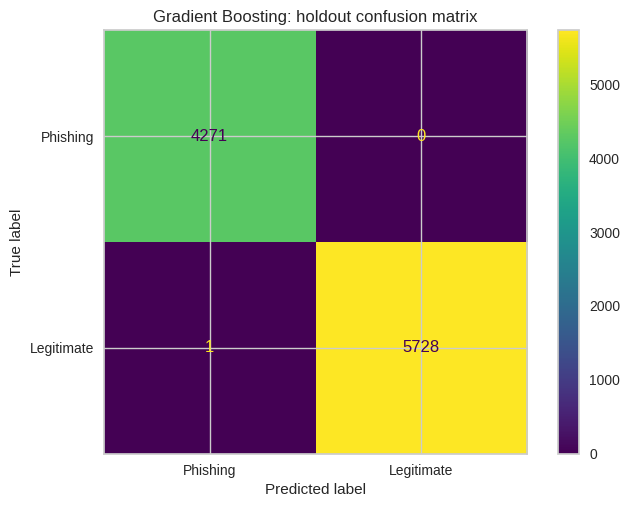

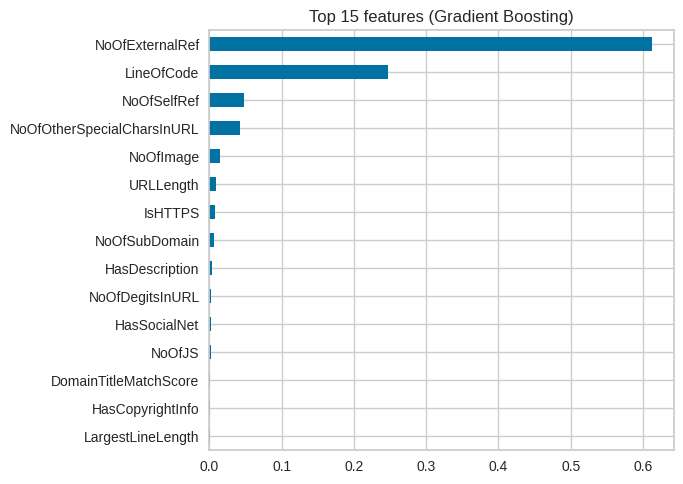

                     Accuracy (A: all)  Accuracy (B: reduced)
Algorithm                                                    
Decision Tree                   1.0000                 0.9976
Random Forest                   1.0000                 0.9998
Gradient Boosting               1.0000                 0.9998
XGBoost                         1.0000                 0.9997
Extra Trees                     0.9999                 0.9993
AdaBoost                        0.9999                 0.9998
LightGBM                        0.9999                 0.9996
Logistic Regression             0.9996                 0.9988
KNN                             0.9972                 0.9964
Naive Bayes                     0.9903                 0.9764


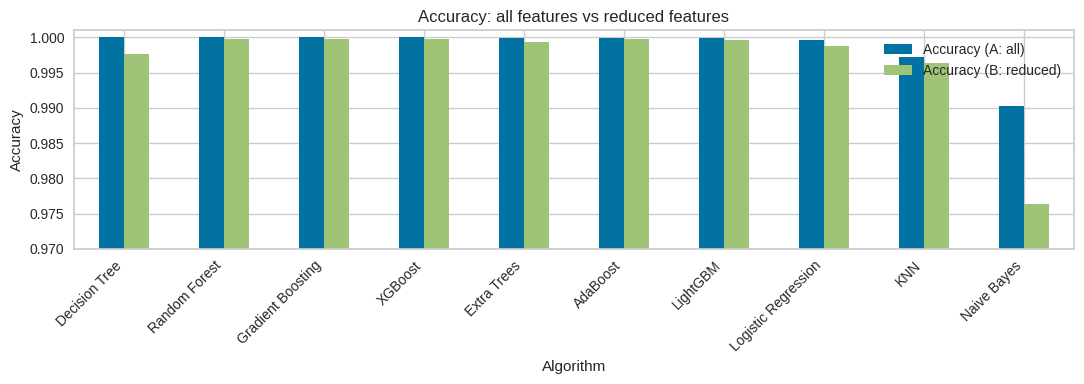

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Best model (Experiment B was the last setup, so this uses the reduced features)
best = create_model("gbc", verbose=False)
print("Parameters:", best.get_params())

Xte, yte = get_config("X_test"), get_config("y_test")
pred = best.predict(Xte)
print(classification_report(yte, pred, target_names=["Phishing", "Legitimate"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(yte, pred),
                       display_labels=["Phishing", "Legitimate"]).plot()
plt.title("Gradient Boosting: holdout confusion matrix")
plt.show()

imp = pd.Series(best.feature_importances_, index=Xte.columns).sort_values().tail(15)
imp.plot(kind="barh", figsize=(7, 5), title="Top 15 features (Gradient Boosting)")
plt.tight_layout(); plt.show()

# A vs B comparison chart
cmp = (table_A.set_index("Algorithm")[["Accuracy"]]
       .join(table_B.set_index("Algorithm")[["Accuracy"]], lsuffix=" (A: all)", rsuffix=" (B: reduced)"))
print(cmp)
cmp.plot(kind="bar", figsize=(11, 4))
plt.ylim(0.97, 1.001); plt.ylabel("Accuracy"); plt.xticks(rotation=45, ha="right")
plt.title("Accuracy: all features vs reduced features")
plt.tight_layout(); plt.show()